# Власний проєкт донавчання: Класифікація емоцій у JSON-форматі

## 1.1. Задача
**Мета:** автоматична класифікація емоційного забарвлення повідомлень користувачів (відгуків, постів, звернень у підтримку) за 6 базовими емоціями (`sadness`, `joy`, `love`, `anger`, `fear`, `surprise`) із поверненням результату у строгому JSON-форматі: `{"emotion": "<label>"}`.

- **Користувач:** аналітичні системи моніторингу соцмереж, CRM або сервіси підтримки клієнтів, яким потрібно автоматично маршрутизувати негативні/тривожні звернення (`anger`, `fear`) у пріоритетну чергу.
- **Вхід:** короткий текст повідомлення користувача англійською мовою.
- **Вихід:** чистий JSON-об'єкт з одним полем `emotion` без зайвого тексту та Markdown-обгорток.
- **Чому потрібне саме донавчання, а не промпт чи RAG:**
  1. **RAG не підходить**, бо задача не потребує пошуку зовнішніх фактів — вона вимагає точного розпізнавання емоційних відтінків.
  2. **Промпту недостатньо**, оскільки базова instruct-модель без донавчання часто плутає близькі емоції (наприклад, `joy` vs `love` або `sadness` vs `fear`), додає зайві пояснення або загортає JSON у блоки ```` ```json ````, що ламає парсер. Крім того, донавчання дозволяє скоротити системний промпт (не передавати щоразу перелік правил), зменшуючи витрати токенів і затримку.

In [1]:
!pip install -q "transformers>=4.55.0" "trl>=1.17" "peft" "datasets" "accelerate" "scikit-learn" "matplotlib" "huggingface_hub"
!pip uninstall -q -y torchao

import gc
import json
import time
import matplotlib.pyplot as plt
import pandas as pd
import torch
from datasets import load_dataset
from peft import LoraConfig
from sklearn.metrics import accuracy_score, f1_score
from transformers import AutoModelForCausalLM, AutoTokenizer
from trl import SFTConfig, SFTTrainer

assert torch.cuda.is_available(), "Увімкніть GPU (T4 або L4)!"
print(f"GPU: {torch.cuda.get_device_name()}")
print(f"Памʼять GPU: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

GPU: NVIDIA L4
Памʼять GPU: 23.7 GB


## 1.2. Модель і дані
- **Модель:** `Qwen/Qwen3-1.7B` (Instruct-версія, 1.7 млрд параметрів). Обрана як оптимальний баланс: вона достатньо компактна, щоб швидко донавчатися через LoRA на T4/L4 GPU (~3.8 GB VRAM), але вже має сильне розуміння нюансів англійської мови.
- **Дані:** датасет [`dair-ai/emotion`](https://huggingface.co/datasets/dair-ai/emotion) (ліцензія: для дослідницьких/освітніх цілей, зібраний із твітів). Містить 20 000 прикладів (16 000 train, 2 000 validation, 2 000 test) із 6 класами: `sadness`, `joy`, `love`, `anger`, `fear`, `surprise`.
- **Поділ:** використовуємо оригінальний поділ датасету (щоб уникнути витоку даних): беремо **2 000** прикладів для тренування, **200** для валідації та **400** для тестування.

In [2]:
MODEL_NAME = "Qwen/Qwen3-1.7B"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

raw_dataset = load_dataset("dair-ai/emotion")
LABELS = raw_dataset["train"].features["label"].names
print("Класи:", LABELS)

# Показуємо кілька прикладів
for ex in raw_dataset["train"].select(range(5)):
    print(f"[{LABELS[ex['label']]:<8}] {ex['text']}")

SHORT_PROMPT = "Classify the emotion of the text. Reply with JSON only."
LONG_PROMPT = (
    "Classify the primary emotion of the user's message.\n"
    'Reply with a single JSON object and nothing else, in the format: {"emotion": "<label>"}\n'
    f"Allowed labels: {', '.join(LABELS)}"
)

def to_messages(example):
    label_name = LABELS[example["label"]]
    answer = json.dumps({"emotion": label_name})
    return {
        "messages": [
            {"role": "system", "content": SHORT_PROMPT},
            {"role": "user", "content": example["text"]},
            {"role": "assistant", "content": answer},
        ],
        "chat_template_kwargs": {"enable_thinking": False},
    }

train_dataset = raw_dataset["train"].shuffle(seed=42).select(range(2000)).map(
    to_messages, remove_columns=raw_dataset["train"].column_names
)
val_dataset = raw_dataset["validation"].shuffle(seed=42).select(range(200)).map(
    to_messages, remove_columns=raw_dataset["validation"].column_names
)
test_dataset = raw_dataset["test"].shuffle(seed=42).select(range(400)).map(
    to_messages, remove_columns=raw_dataset["test"].column_names
)

print(f"\nРозміри вибірок -> Train: {len(train_dataset)}, Val: {len(val_dataset)}, Test: {len(test_dataset)}")

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (11 outputs left out)

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/200 [00:00<?, ? examples/s]

Map:   0%|          | 0/400 [00:00<?, ? examples/s]


Розміри вибірок -> Train: 2000, Val: 200, Test: 400


In [3]:
def classify_batch(model, texts, system_prompt, max_new_tokens=30):
    prompts = [
        tokenizer.apply_chat_template(
            [{"role": "system", "content": system_prompt}, {"role": "user", "content": t}],
            tokenize=False, add_generation_prompt=True, enable_thinking=False,
        )
        for t in texts
    ]
    tokenizer.padding_side = "left"
    inputs = tokenizer(prompts, return_tensors="pt", padding=True).to(model.device)
    tokenizer.padding_side = "right"
    with torch.no_grad():
        outputs = model.generate(
            **inputs, max_new_tokens=max_new_tokens, do_sample=False, pad_token_id=tokenizer.pad_token_id
        )
    new_tokens = outputs[:, inputs["input_ids"].shape[1]:]
    return [ans.strip() for ans in tokenizer.batch_decode(new_tokens, skip_special_tokens=True)]

def parse_emotion(answer):
    text = answer.strip()
    if text.startswith("```"):
        text = text.strip("`").removeprefix("json").strip()
    try:
        obj = json.loads(text)
        if isinstance(obj, dict) and "emotion" in obj:
            return obj["emotion"]
    except json.JSONDecodeError:
        pass
    return None

def is_clean_json(answer):
    try:
        json.loads(answer)
        return True
    except json.JSONDecodeError:
        return False

def evaluate(model, system_prompt, batch_size=32):
    model.eval()
    texts = [ex["messages"][1]["content"] for ex in test_dataset]
    y_true = [json.loads(ex["messages"][2]["content"])["emotion"] for ex in test_dataset]

    answers = []
    for i in range(0, len(texts), batch_size):
        answers += classify_batch(model, texts[i:i + batch_size], system_prompt)

    clean = sum(is_clean_json(a) for a in answers)
    preds = [parse_emotion(a) for a in answers]
    valid = sum(p in LABELS for p in preds)

    y_pred_for_metrics = [p if p in LABELS else "INVALID" for p in preds]
    acc = accuracy_score(y_true, y_pred_for_metrics)
    f1 = f1_score(y_true, y_pred_for_metrics, labels=LABELS, average="macro", zero_division=0)

    metrics = {
        "Чистий JSON, %": round(100 * clean / len(answers), 2),
        "Валідний JSON (з дозволеним класом), %": round(100 * valid / len(answers), 2),
        "Accuracy, %": round(100 * acc, 2),
        "Macro F1, %": round(100 * f1, 2),
    }
    details = list(zip(texts, y_true, answers, preds))
    return metrics, details

# Завантажуємо базову модель та оцінюємо ДО донавчання (з детальним промптом)
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=torch.float16, device_map="auto")
before_metrics, before_details = evaluate(model, LONG_PROMPT)
print("Метрики ДО донавчання (з детальним промптом):")
print(pd.Series(before_metrics))

print("\nПриклади відповідей ДО донавчання (перші 8):")
for text, true_lbl, raw_ans, _ in before_details[:8]:
    print(f"{text}\n   Еталон: {true_lbl} | Модель: {raw_ans}\n" + "-"*50)

model.safetensors.index.json:   0%|          | 0.00/25.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Метрики ДО донавчання (з детальним промптом):
Чистий JSON, %                            100.00
Валідний JSON (з дозволеним класом), %     97.75
Accuracy, %                                53.25
Macro F1, %                                40.34
dtype: float64

Приклади відповідей ДО донавчання (перші 8):
i was feeling really troubled and down over what my dad said
   Еталон: sadness | Модель: {"emotion": "sadness"}
--------------------------------------------------
i feel so thrilled to have three such distinguished individuals such as yourselves here
   Еталон: joy | Модель: {"emotion": "joy"}
--------------------------------------------------
i feel is that the most likeable characters aren t important enough to the plot
   Еталон: joy | Модель: {"emotion": "fear"}
--------------------------------------------------
i tune out the rest of the world and focus on the rhythm of the needles and the softness of the yarn and for that time i feel my most peaceful
   Еталон: joy | Модель: {"emot

Tokenizing train dataset:   0%|          | 0/2000 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/2000 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/2000 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/2000 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

Building labels for eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

Dropping fully masked examples from eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

trainable params: 17,432,576 || all params: 1,738,007,552 || trainable%: 1.0030


Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
20,0.531915,0.163856,0.105596,0.942702,9090.000000
40,0.147023,0.151939,0.068991,0.958160,18618.000000
60,0.131185,0.131725,0.096007,0.970594,28146.000000
80,0.095079,0.091399,0.076598,0.970184,37576.000000
100,0.097448,0.085872,0.088422,0.973051,46923.000000
120,0.079597,0.082508,0.090640,0.975440,56135.000000



Тривалість тренування: 2.55 хв
Пікова памʼять GPU: 3.88 GB


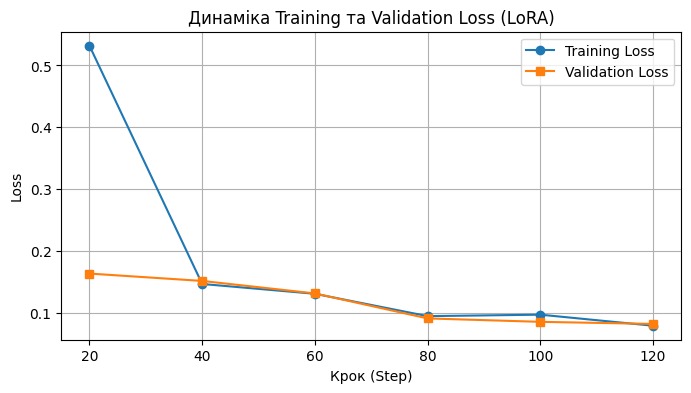

In [4]:
peft_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    target_modules="all-linear",
    task_type="CAUSAL_LM",
)

sft_config = SFTConfig(
    output_dir="qwen3-1.7b-emotion-lora",
    max_length=256,
    per_device_train_batch_size=4,
    gradient_accumulation_steps=2,
    per_device_eval_batch_size=8,    # ефективний batch size = 8
    learning_rate=2e-4,
    lr_scheduler_type="cosine",
    warmup_steps=10,
    max_steps=120,                   # 120 * 8 = 960 прикладів
    eval_strategy="steps",
    eval_steps=20,
    logging_steps=20,
    fp16=True,
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},
    assistant_only_loss=True,
    save_strategy="no",
    report_to="none",
)

torch.cuda.reset_peak_memory_stats()
trainer = SFTTrainer(
    model=model,
    args=sft_config,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    processing_class=tokenizer,
    peft_config=peft_config,
)
trainer.model.print_trainable_parameters()

start = time.time()
trainer.train()
train_minutes = (time.time() - start) / 60
peak_mem_gb = torch.cuda.max_memory_allocated() / 1e9

print(f"\nТривалість тренування: {train_minutes:.2f} хв")
print(f"Пікова памʼять GPU: {peak_mem_gb:.2f} GB")

# Будуємо графік Training vs Validation Loss
history = trainer.state.log_history
train_steps = [h["step"] for h in history if "loss" in h]
train_loss = [h["loss"] for h in history if "loss" in h]
eval_steps = [h["step"] for h in history if "eval_loss" in h]
eval_loss = [h["eval_loss"] for h in history if "eval_loss" in h]

plt.figure(figsize=(8, 4))
plt.plot(train_steps, train_loss, marker="o", label="Training Loss")
plt.plot(eval_steps, eval_loss, marker="s", label="Validation Loss")
plt.xlabel("Крок (Step)")
plt.ylabel("Loss")
plt.title("Динаміка Training та Validation Loss (LoRA)")
plt.legend()
plt.grid(True)
plt.show()

In [5]:
after_metrics, after_details = evaluate(trainer.model, SHORT_PROMPT)

comparison_df = pd.DataFrame({
    "До донавчання (LONG_PROMPT)": before_metrics,
    "Після LoRA (SHORT_PROMPT)": after_metrics,
})
display(comparison_df)

print("\nПорівняння на тих самих 8 прикладах:")
for i in range(8):
    text, true_lbl, raw_before, _ = before_details[i]
    _, _, raw_after, _ = after_details[i]
    print(f"📩 {text}\n   Еталон: {true_lbl}\n   До:    {raw_before}\n   Після: {raw_after}\n" + "-"*50)

print("\nАналіз помилок донавченої моделі (перші 5 помилок):")
errors = [d for d in after_details if d[3] != d[1]]
print(f"Усього помилок: {len(errors)} з {len(after_details)}")
for text, true_lbl, raw_after, pred_lbl in errors[:5]:
    print(f"❌ Текст: {text}\n   Еталон: {true_lbl} | Прогноз: {pred_lbl} ({raw_after})\n")

# Перевірка, чи не деградувала модель на загальних питаннях (catastrophic forgetting)
print("\nПеревірка на загальних запитах поза задачею:")
general_questions = [
    "Explain in two sentences what photosynthesis is.",
    "What is the capital of Ukraine?",
]
for q in general_questions:
    ans = classify_batch(trainer.model, [q], "You are a helpful assistant.", max_new_tokens=80)[0]
    print(f"❓ {q}\n🤖 {ans}\n")

,До донавчання (LONG_PROMPT),Після LoRA (SHORT_PROMPT)
"Чистий JSON, %",100.00,100.00
"Валідний JSON (з дозволеним класом), %",97.75,100.00
"Accuracy, %",53.25,80.50
"Macro F1, %",40.34,71.84



Порівняння на тих самих 8 прикладах:
📩 i was feeling really troubled and down over what my dad said
   Еталон: sadness
   До:    {"emotion": "sadness"}
   Після: {"emotion": "sadness"}
--------------------------------------------------
📩 i feel so thrilled to have three such distinguished individuals such as yourselves here
   Еталон: joy
   До:    {"emotion": "joy"}
   Після: {"emotion": "joy"}
--------------------------------------------------
📩 i feel is that the most likeable characters aren t important enough to the plot
   Еталон: joy
   До:    {"emotion": "fear"}
   Після: {"emotion": "joy"}
--------------------------------------------------
📩 i tune out the rest of the world and focus on the rhythm of the needles and the softness of the yarn and for that time i feel my most peaceful
   Еталон: joy
   До:    {"emotion": "joy"}
   Після: {"emotion": "joy"}
--------------------------------------------------
📩 i sit here writing this i feel unhappy inside
   Еталон: sadness
   До:

In [6]:
from huggingface_hub import login

login()

REPO_ID = "EduardKrutii/qwen3-1.7b-emotion-lora"

trainer.model.push_to_hub(REPO_ID)
tokenizer.push_to_hub(REPO_ID)
print(f"Адаптер успішно опубліковано: https://huggingface.co/{REPO_ID}")

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...adapter_model.safetensors:   0%|          | 45.8kB / 69.8MB            

Validating                    :           |   0%            

README.md:   0%|          | 0.00/5.17k [00:00<?, ?B/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...mpefehmuod/tokenizer.json:   0%|          | 28.5kB / 11.4MB            

Validating                    :           |   0%            

Адаптер успішно опубліковано: https://huggingface.co/EduardKrutii/qwen3-1.7b-emotion-lora


## 1.6. Мій звіт

- **Задача і чому потрібне донавчання:**
  Автоматична класифікація емоційного забарвлення повідомлень користувачів за 6 класами (`sadness`, `joy`, `love`, `anger`, `fear`, `surprise`) із виводом у строгому JSON-форматі `{"emotion": "<label>"}` для систем аналітики відгуків та маршрутизації звернень. RAG для цієї задачі не підходить (немає потреби в пошуку зовнішніх фактів), а звичайного промпту недостатньо: базова модель погано розрізняє близькі емоції, іноді вигадує класи поза дозволеним списком (2.25% невалідних міток) і вимагає передавати довгий системний промпт у кожному запиті.

- **Модель і дані:**
  - **Модель:** `Qwen/Qwen3-1.7B` (Instruct, 1.7 млрд параметрів) — оптимальний баланс якості та вимог до пам'яті GPU.
  - **Дані:** датасет [`dair-ai/emotion`](https://huggingface.co/datasets/dair-ai/emotion) (6 класів емоцій із твітів). Використано оригінальний поділ без витоку даних: **2 000** прикладів для тренування, **200** для валідації та **400** для тестування.

- **Метрика й результат до донавчання:**
  Обрано **Accuracy**, **Macro F1** (оскільки класи емоцій незбалансовані, наприклад `surprise` трапляється значно рідше за `joy`) та **частку валідного JSON із дозволеним класом**.
  До донавчання (з детальним `LONG_PROMPT` на 400 тестових прикладах):
  - Чистий JSON: **100.00%**
  - Валідний JSON (дозволений клас): **97.75%**
  - Accuracy: **53.25%**
  - Macro F1: **40.34%**

- **Метод донавчання й гіперпараметри:**
  Використано **SFT з LoRA** (`r=16`, `lora_alpha=32`, `lora_dropout=0.05`, `target_modules="all-linear"`). Тренувалося лише **1.003%** параметрів (17.4 млн із 1.74 млрд).
  Гіперпараметри: `learning_rate=2e-4` (cosine scheduler, `warmup_steps=10`), ефективний `batch_size=8` (`4 × 2`), `max_steps=120`, `fp16=True`, `assistant_only_loss=True`, `enable_thinking=False`.
  Запуск виконувався в Google Colab на **NVIDIA L4 GPU**:
  - Тривалість тренування: **2.55 хв** (загальний час виконання ноутбуку — 4 хв 30 сек).
  - Пікова памʼять GPU: **3.88 GB**.
  - Динаміка loss: Training Loss знизився з `0.5319` до `0.0796`, Validation Loss — з `0.1639` до `0.0825`. Обидві криві плавно сходяться без ознак перенавчання.

- **Результат після донавчання:**
  На тому самому тестовому наборі (400 прикладів), але вже з коротким промптом `SHORT_PROMPT` (без переліку класів):
  - Чистий JSON: **100.00%**
  - Валідний JSON (дозволений клас): **100.00%** (+2.25%)
  - Accuracy: **80.50%** (+27.25%)
  - Macro F1: **71.84%** (+31.50%)
  - **Перевірка на загальних питаннях:** модель зберегла загальні знання (коректно пояснила фотосинтез і назвала столицю України — Київ), катастрофічного забування (catastrophic forgetting) не виявлено.

- **Аналіз помилок:**
  Донавчена модель допустила **78 помилок із 400**. Більшість із них припадає на семантично близькі або неоднозначні межі емоцій у текстах соцмереж:
  - `anger` vs `fear` (наприклад, *"i get the feeling that this could be dangerous"* або *"feel rushed and stressed"* — модель логічно класифікувала як `fear`, хоча в датасеті стоїть мітка `anger`);
  - `joy` vs `love` (наприклад, тексти про пристрасть або прийняття ситуації);
  - `fear` vs `sadness` (відчуття тиску та пригніченості).
  
  Це свідчить про те, що помилки здебільшого пов'язані із суб'єктивністю людської розмітки твітів, а не зі збоями формату.

- **Висновок:**
  Донавчання `Qwen3-1.7B` методом LoRA за 2.55 хвилини та 3.88 GB VRAM дозволило радикально підняти якість класифікації емоцій (Accuracy з 53.25% до 80.50%, Macro F1 з 40.34% до 71.84%), досягти 100% валідності JSON і скоротити системний промпт без втрати загальних здібностей моделі.

- **Посилання на опублікований LoRA-адаптер (Hugging Face Hub):**
  https://huggingface.co/EduardKrutii/qwen3-1.7b-emotion-lora